모두마켓 데이터 생성 완료
customers: (300, 6) | products: (40, 3) | orders: (2000, 7)

[빠르게 둘러보기]
customers 결측: 51 건
orders 결측: 51 건
타입: Series / True 개수: 62
앞 5개 미리보기: [False, False, True, False, True]

서울 고객 수: 62


,customer_id,age,gender,region,membership,income
2,C0003,41,F,서울,premium,8500.0
4,C0005,33,M,서울,basic,2500.0
5,C0006,999,F,서울,basic,NaN


,customer_id,age,membership
4,C0005,33,basic
11,C0012,31,basic
21,C0022,33,basic
25,C0026,36,premium
41,C0042,37,basic


,order_id,amount
0,O00001,29900.0
1,O00002,149700.0
2,O00003,NaN
3,O00004,29900.0
4,O00005,19800.0
5,O00006,129900.0
6,O00007,39800.0
7,O00008,29900.0
8,O00009,89900.0
9,O00010,9900.0



== amount > 0 인 행 ==


...

,order_id,amount


결측 포함 필터:


,order_id,amount
0,O00001,29900.0
1,O00002,149700.0
2,O00003,NaN
3,O00004,29900.0
4,O00005,19800.0
5,O00006,129900.0
6,O00007,39800.0
7,O00008,29900.0
8,O00009,89900.0
9,O00010,9900.0



결측 명시적 제외:


,order_id,amount
0,O00001,29900.0
1,O00002,149700.0
3,O00004,29900.0
4,O00005,19800.0
5,O00006,129900.0
6,O00007,39800.0
7,O00008,29900.0
8,O00009,89900.0
9,O00010,9900.0


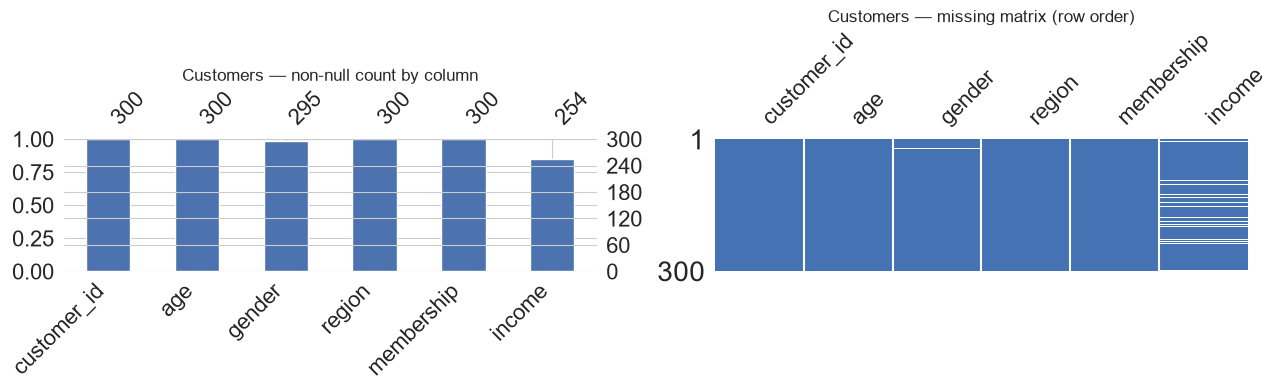

In [ ]:
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno   # 결측 패턴 시각화 전용 라이브러리 (Part 3에서 사용)

warnings.filterwarnings("ignore")

# 재현성: 같은 난수를 항상 같게 만들어 결과가 매번 동일하도록 고정합니다.
np.random.seed(42)

# 한글 폰트 설정 (운영체제별 분기)
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

#print("준비 완료! 라이브러리 버전을 확인합니다.")
#print("numpy :", np.__version__)
#print("pandas:", pd.__version__)

# ─────────────────────────────────────────────
# 모두마켓 데이터 생성 (D+003 버전)
# - 어제 발견한 오염을 그대로 가져오되, 결측/이상치를 더 다양하게 심습니다.
# - 이 셀 하나로 오늘 쓸 데이터가 전부 준비됩니다 (이 노트북은 단독 실행 가능).
# ─────────────────────────────────────────────
np.random.seed(42)

# 1) 고객(customers)
n_customers = 300
customers = pd.DataFrame({
    "customer_id": [f"C{str(i).zfill(4)}" for i in range(1, n_customers + 1)],
    "age": np.random.normal(35, 9, n_customers).round().astype(int),
    "gender": np.random.choice(["M", "F"], n_customers),
    "region": np.random.choice(["서울", "경기", "부산", "인천", "대구"], n_customers),
    "membership": np.random.choice(["basic", "premium", "vip"], n_customers, p=[0.6, 0.3, 0.1]),
    "income": np.random.choice([2500, 3500, 4500, 6000, 8500], n_customers).astype(float),
})

# 오염 심기 — 나이 이상치
customers.loc[5, "age"] = 999            # 입력 실수로 보이는 이상치
customers.loc[10, "age"] = -3            # 음수 나이(불가능한 값)
customers.loc[15, "age"] = 120           # 매우 큰 값 (이상치 후보)

# 오염 심기 — 성별 결측 (관찰자가 응답을 안 받았을 가능성: MCAR에 가까움)
customers.loc[[20, 21, 22, 70, 120], "gender"] = np.nan

# 오염 심기 — 소득 결측 (고소득 고객일수록 응답 거절 → MNAR 신호)
high_income_mask = customers["income"] >= 6000
high_idx = customers[high_income_mask].sample(frac=0.4, random_state=1).index
customers.loc[high_idx, "income"] = np.nan

# 2) 상품(products)
categories = ["패션", "뷰티", "식품", "가전", "도서"]
n_products = 40
products = pd.DataFrame({
    "product_id": [f"P{str(i).zfill(3)}" for i in range(1, n_products + 1)],
    "category": np.random.choice(categories, n_products),
    "price": np.random.choice([9900, 19900, 29900, 49900, 89900, 129900], n_products),
})

# 3) 주문(orders)
n_orders = 2000
order_customer = np.random.choice(customers["customer_id"], n_orders)
order_product = np.random.choice(products["product_id"], n_orders)
price_map = products.set_index("product_id")["price"]
quantity = np.random.choice([1, 1, 1, 2, 2, 3], n_orders)
amount = price_map.loc[order_product].values * quantity

orders = pd.DataFrame({
    "order_id": [f"O{str(i).zfill(5)}" for i in range(1, n_orders + 1)],
    "customer_id": order_customer,
    "product_id": order_product,
    "category": products.set_index("product_id").loc[order_product, "category"].values,
    "quantity": quantity,
    "amount": amount.astype(float),
    "channel": np.random.choice(["web", "app"], n_orders, p=[0.5, 0.5]),
})

# 오염 심기 — 금액 결측 (일부 채널에서만 결측이 더 잦음 → MAR 신호)
app_mask = orders["channel"] == "app"
app_idx = orders[app_mask].sample(frac=0.04, random_state=2).index
web_idx = orders[~app_mask].sample(frac=0.01, random_state=3).index
orders.loc[app_idx.union(web_idx), "amount"] = np.nan

# 오염 심기 — 수량 이상치
orders.loc[7, "quantity"] = 100         # 비정상적으로 큰 주문 수량
orders.loc[1900, "quantity"] = 50       # 또 하나의 극단값
orders.loc[1500, "amount"] = 5_000_000  # 금액 자체의 극단값

print("모두마켓 데이터 생성 완료")
print("customers:", customers.shape, "| products:", products.shape, "| orders:", orders.shape)
print("\n[빠르게 둘러보기]")
print("customers 결측:", customers.isnull().sum().sum(), "건")
print("orders 결측:", orders.isnull().sum().sum(), "건")

# 예제: 불리언 인덱싱 — 조건에 맞는 행 전부
# 조건(불리언 Series) 만들기
is_seoul = customers["region"] == "서울"
print("타입:", type(is_seoul).__name__, "/ True 개수:", is_seoul.sum())
print("앞 5개 미리보기:", is_seoul.head().tolist())

# 그 조건을 [ ]에 그대로 — 어제 본 패턴
seoul_customers = customers[is_seoul]
print("\n서울 고객 수:", len(seoul_customers))
display(seoul_customers.head(3))

# 예제: .loc + 불리언 — '조건 만족 행의 특정 열만' 가리키기 (오늘의 핵심 패턴)
# 30대 서울 고객의 멤버십만 꺼내기
mask = (customers["region"] == "서울") & (customers["age"].between(30, 39))
display(customers.loc[mask, ["customer_id", "age", "membership"]].head())

# NaN과 비교는 항상 False 입니다 — 직관과 다름
sample = orders[["order_id", "amount"]].head(10).copy()
sample.loc[2, "amount"] = np.nan
display(sample)

print("\n== amount > 0 인 행 ==")
display(sample[sample["amount"] > 0])     # NaN 행은 제외됨 (조건이 False로 평가)

print("\n== amount <= 0 인 행 ==")
display(sample[sample["amount"] <= 0])    # 역시 NaN은 제외됨
# 해결책 1) 결측을 명시적으로 포함하기
mask_with_na = (sample["amount"] > 0) | (sample["amount"].isnull())
print("결측 포함 필터:")
display(sample[mask_with_na])

# 해결책 2) 결측을 명시적으로 제외하기
mask_no_na = (sample["amount"] > 0) & (sample["amount"].notna())
print("\n결측 명시적 제외:")
display(sample[mask_no_na])

# 5종 세트 ⑤ — missingno로 결측 패턴 시각화 (bar + matrix)
# missingno는 결측 시각화에 특화된 라이브러리입니다. 두 가지를 자주 씁니다.
#   bar    : 컬럼별 '비어 있지 않은' 막대 — 한눈에 결측이 많은 컬럼 식별
#   matrix : 행 순서별 결측 위치 — '어디가 함께 비는가' 패턴 발견


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
msno.bar(customers, ax=axes[0], color="#4C72B0")
axes[0].set_title("Customers — non-null count by column")
msno.matrix(customers, ax=axes[1], color=(0.27, 0.45, 0.70), sparkline=False)
axes[1].set_title("Customers — missing matrix (row order)")
plt.tight_layout()
plt.show()



In [2]:
%pip install numpy pandas matplotlib seaborn missingno

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.6 MB 11.8 MB/s eta 0:00:01
   -------------- ------------------------- 4.5/12.6 MB 11.2 MB/s eta 0:00:01
   ---------------------- ----------------- 7.1/12.6 MB 11.2 MB/s eta 0:00:01
   ------------------------------ --------- 9.4/12.6 MB 11.3 MB/s eta 0:00:01
   -------------------------------------- - 12.1/12.6 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 10.8 MB/s  0:00:01
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.7 MB 12.2 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.7 MB 11.9 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.7 MB 11.9 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.7 MB 12.0 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 10.9 MB/s  0:00:00
   ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
